# Neural network for image classification

## Approach 1 - extract all the pixels

In [21]:
import cv2
import numpy as np
import os
import zipfile
import tensorflow as tf
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [22]:
tf.__version__

'2.21.0'

### Extracting pixels from images

In [23]:
def display_image(img, title: str = None):
    if len(img.shape) == 2:
        plt.imshow(img, cmap='gray')
    if len(img.shape) == 3:
        if img.shape[2] == 3:
            img_display = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            plt.imshow(img_display)
        elif img.shape[2] == 4:
            plt.imshow(img)

    if title:
        plt.title(title)

    plt.axis('off')
    plt.show()

In [24]:
path = 'drive/Datasets/homer_bart_1.zip'
zip_object = zipfile.ZipFile(file = path, mode = 'r')
zip_object.extractall('./')
zip_object.close()

In [25]:
directory = './homer_bart_1'
files = [os.path.join(directory, f) for f in sorted(os.listdir(directory))
         if f.lower().endswith(('.bmp', '.png', '.jpg', '.jpeg'))]
print(files)

['./homer_bart_1/bart1.bmp', './homer_bart_1/bart10.bmp', './homer_bart_1/bart100.bmp', './homer_bart_1/bart101.bmp', './homer_bart_1/bart102.bmp', './homer_bart_1/bart103.bmp', './homer_bart_1/bart104.bmp', './homer_bart_1/bart105.bmp', './homer_bart_1/bart106.bmp', './homer_bart_1/bart108.bmp', './homer_bart_1/bart109.bmp', './homer_bart_1/bart11.bmp', './homer_bart_1/bart110.bmp', './homer_bart_1/bart111.bmp', './homer_bart_1/bart112.bmp', './homer_bart_1/bart113.bmp', './homer_bart_1/bart114.bmp', './homer_bart_1/bart115.bmp', './homer_bart_1/bart116.bmp', './homer_bart_1/bart117.bmp', './homer_bart_1/bart118.bmp', './homer_bart_1/bart119.bmp', './homer_bart_1/bart12.bmp', './homer_bart_1/bart120.bmp', './homer_bart_1/bart121.bmp', './homer_bart_1/bart122.bmp', './homer_bart_1/bart123.bmp', './homer_bart_1/bart124.bmp', './homer_bart_1/bart125.bmp', './homer_bart_1/bart126.bmp', './homer_bart_1/bart127.bmp', './homer_bart_1/bart128.bmp', './homer_bart_1/bart13.bmp', './homer_bart_1

In [26]:
type(files)

list

In [27]:
height, width = 128, 128

In [28]:
images = []
classes = []

In [29]:
cv2.imread(files[0]).shape

(497, 326, 3)

In [30]:
128 * 128 * 3, 128 * 128

(49152, 16384)

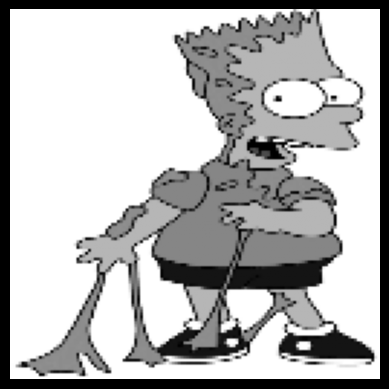

(16384,)
0


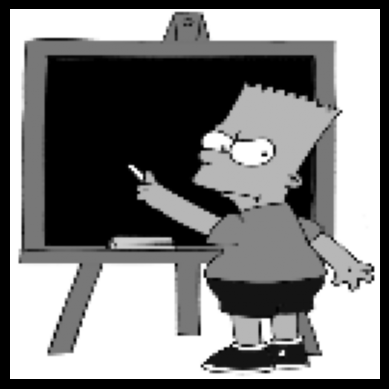

(16384,)
0


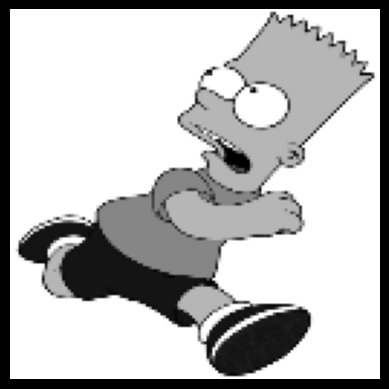

(16384,)
0


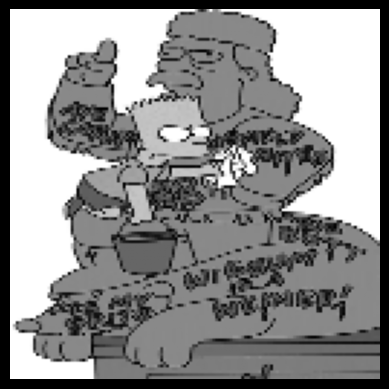

(16384,)
0


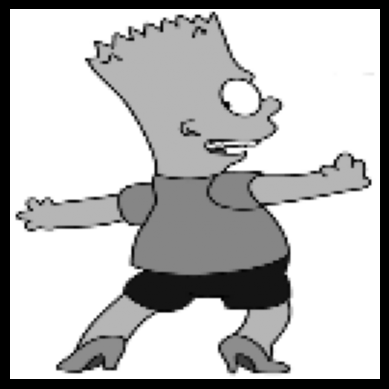

(16384,)
0


In [31]:
images = []
classes = []
counter = 0

for image_path in files:
  # print(image_path)
  image = cv2.imread(image_path)
  if image is None:
    continue

  image = cv2.resize(image, (width, height))
  image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

  image = image.ravel()

  images.append(image)

  image_name = os.path.basename(os.path.normpath(image_path))
  if image_name.startswith('b'):
    class_name = 0
  else:
    class_name = 1

  classes.append(class_name)

  if counter < 5:
      display_image(image.reshape(height, width))
      print(image.shape)
      print(class_name)

  counter += 1


In [32]:
images

[array([255, 255, 255, ..., 255, 255, 255], shape=(16384,), dtype=uint8),
 array([254, 254, 254, ..., 254, 254, 254], shape=(16384,), dtype=uint8),
 array([255, 255, 255, ..., 255, 255, 255], shape=(16384,), dtype=uint8),
 array([255, 255, 255, ..., 128, 123, 124], shape=(16384,), dtype=uint8),
 array([255, 255, 255, ..., 255, 255, 255], shape=(16384,), dtype=uint8),
 array([255, 255, 255, ..., 255, 255, 255], shape=(16384,), dtype=uint8),
 array([255, 255, 255, ..., 255, 255, 255], shape=(16384,), dtype=uint8),
 array([255, 255, 255, ..., 255, 255, 255], shape=(16384,), dtype=uint8),
 array([255, 255, 255, ..., 255, 255, 255], shape=(16384,), dtype=uint8),
 array([255, 255, 255, ..., 255, 255, 255], shape=(16384,), dtype=uint8),
 array([255, 255, 255, ..., 255, 255, 255], shape=(16384,), dtype=uint8),
 array([254, 254, 254, ..., 254, 254, 254], shape=(16384,), dtype=uint8),
 array([255, 255, 255, ..., 255, 255, 255], shape=(16384,), dtype=uint8),
 array([255, 255, 255, ..., 255, 255, 

In [33]:
print(classes)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [34]:
type(images), type(classes)

(list, list)

In [35]:
X = np.asarray(images)
y = np.asarray(classes)

In [36]:
type(X), type(y)

(numpy.ndarray, numpy.ndarray)

In [37]:
X.shape # 128 * 128

(269, 16384)

In [38]:
y.shape

(269,)

In [39]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1])

In [40]:
X[0].reshape(width, height).shape

(128, 128)

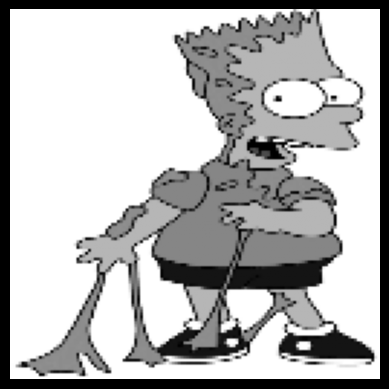

In [41]:
display_image(X[0].reshape(width, height))

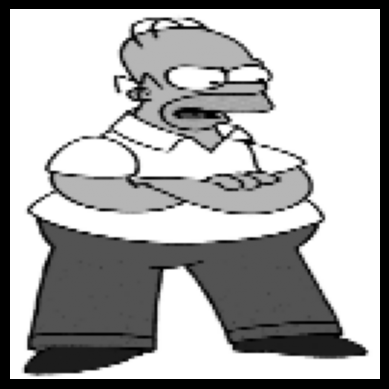

In [42]:
display_image(X[200].reshape(width, height))

<Axes: ylabel='count'>

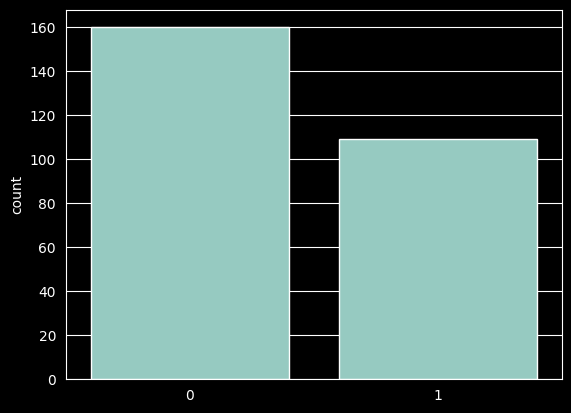

In [43]:
sns.countplot(x=y)

In [44]:
np.unique(y, return_counts=True)

(array([0, 1]), array([160, 109]))

### Normalizing the data

In [45]:
X[0].max(), X[0].min()

(np.uint8(255), np.uint8(0))

In [46]:
# pixel values have a fixed range, so scaling does not learn from test data.
X = X.astype(np.float32) / 255.0

In [47]:
X[0].max(), X[0].min()

(np.float32(1.0), np.float32(0.0))

In [48]:
X[1]

array([0.99607843, 0.99607843, 0.99607843, ..., 0.99607843, 0.99607843,
       0.99607843], shape=(16384,), dtype=float32)

### Train and test set

In [49]:
from sklearn.model_selection import train_test_split

In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

In [51]:
X_train.shape, y_train.shape

((215, 16384), (215,))

In [52]:
X_test.shape, y_test.shape

((54, 16384), (54,))

### Building and training the neural network

In [53]:
16384 * 128 + 128 * 128

2113536

In [124]:
# 16384 -> 128 -> 128 -> 1
network1 = tf.keras.models.Sequential()
network1.add(tf.keras.layers.Input(shape=(16384,)))
network1.add(tf.keras.layers.Dense(units=128, activation='relu'))
network1.add(tf.keras.layers.Dense(units=128, activation='relu'))
network1.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

In [55]:
network1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,113,921 (8.06 MB)

 Trainable params: 2,113,921 (8.06 MB)

 Non-trainable params: 0 (0.00 B)

In [56]:
# https://keras.io/api/optimizers/
# https://keras.io/api/losses/
network1.compile(optimizer='Adam', loss='binary_crossentropy', metrics = ['accuracy'])

In [57]:
history = network1.fit(X_train, y_train, epochs=50)

Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.5628 - loss: 3.5366
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5767 - loss: 0.8357
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5116 - loss: 0.7121
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.5488 - loss: 0.7879
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.5023 - loss: 0.7624
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.5070 - loss: 0.7226
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.5209 - loss: 0.6904
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.5488 - loss: 0.6816
Epoch 9/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.6093 - loss: 0.7242
Epoch 10/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.5628 - loss: 0.7506
Epoch 11/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5349 - loss: 0.6673
Epoch 12/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.6326 - loss: 0.6094
E

### Evaluating the neural network

In [58]:
history.history.keys()

dict_keys(['accuracy', 'loss'])

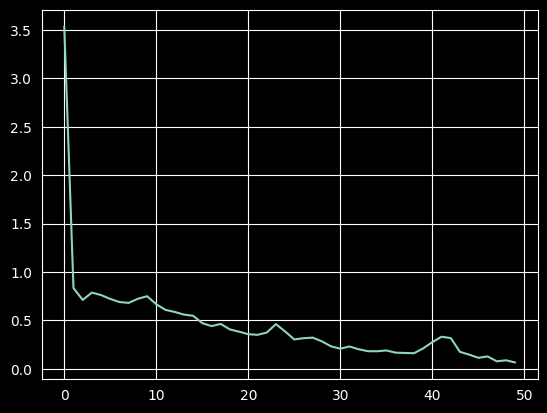

In [59]:
plt.plot(history.history['loss']);

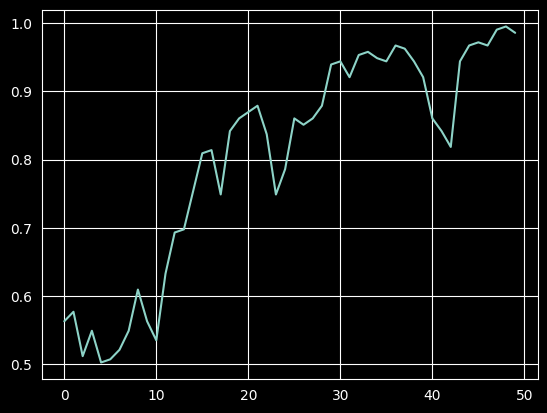

In [60]:
plt.plot(history.history['accuracy']);

In [61]:
X_test.shape

(54, 16384)

In [62]:
predictions = network1.predict(X_test)
predictions

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step


array([[0.97890997],
       [0.8891465 ],
       [0.7932457 ],
       [0.11002938],
       [0.491761  ],
       [0.70794845],
       [0.86201334],
       [0.16104159],
       [0.41973126],
       [0.92353755],
       [0.45385247],
       [0.63787276],
       [0.00462388],
       [0.8520072 ],
       [0.14857903],
       [0.17262132],
       [0.4606182 ],
       [0.70991975],
       [0.10376109],
       [0.7612722 ],
       [0.88498163],
       [0.17047952],
       [0.09958194],
       [0.74789906],
       [0.0450518 ],
       [0.8518242 ],
       [0.9790598 ],
       [0.17045248],
       [0.55797726],
       [0.957676  ],
       [0.40164846],
       [0.39460272],
       [0.03753317],
       [0.6733135 ],
       [0.9959003 ],
       [0.1588033 ],
       [0.18836676],
       [0.3620277 ],
       [0.31658444],
       [0.18708575],
       [0.14008778],
       [0.14408131],
       [0.08119192],
       [0.45598602],
       [0.83956057],
       [0.7697282 ],
       [0.842711  ],
       [0.576

In [63]:
# 0 False - Bart
# 1 True  - Homer

In [64]:
predictions = (predictions > 0.5)
predictions

array([[ True],
       [ True],
       [ True],
       [False],
       [False],
       [ True],
       [ True],
       [False],
       [False],
       [ True],
       [False],
       [ True],
       [False],
       [ True],
       [False],
       [False],
       [False],
       [ True],
       [False],
       [ True],
       [ True],
       [False],
       [False],
       [ True],
       [False],
       [ True],
       [ True],
       [False],
       [ True],
       [ True],
       [False],
       [False],
       [False],
       [ True],
       [ True],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [False],
       [False],
       [False],
       [ True]])

In [65]:
y_test

array([1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1,
       1, 1, 0, 1, 0, 1, 0, 0, 0, 0])

In [66]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, predictions)

0.6111111111111112

In [67]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, predictions)
cm

array([[20, 12],
       [ 9, 13]])

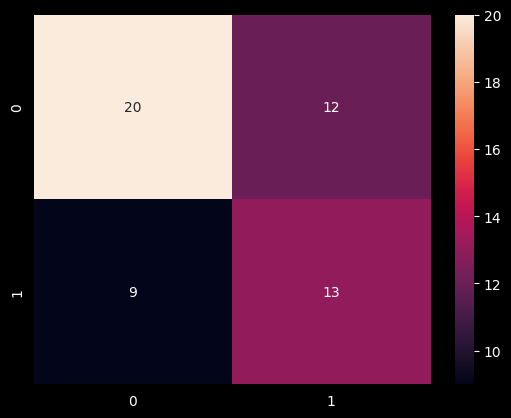

In [68]:
sns.heatmap(cm, annot=True);

In [69]:
from sklearn.metrics import classification_report
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.69      0.62      0.66        32
           1       0.52      0.59      0.55        22

    accuracy                           0.61        54
   macro avg       0.60      0.61      0.60        54
weighted avg       0.62      0.61      0.61        54



### Saving and loading the network

In [70]:
model_json = network1.to_json()
with open('network1.json', 'w') as json_file:
  json_file.write(model_json)

In [71]:
network1.save_weights('network1.weights.h5')

In [72]:
with open('network1.json') as json_file:
  json_saved_model = json_file.read()
json_saved_model

'{"module": "keras", "class_name": "Sequential", "config": {"name": "sequential", "trainable": true, "dtype": {"module": "keras", "class_name": "DTypePolicy", "config": {"name": "float32"}, "registered_name": null}, "layers": [{"module": "keras.layers", "class_name": "InputLayer", "config": {"batch_shape": [null, 16384], "dtype": "float32", "sparse": false, "ragged": false, "name": "input_layer", "optional": false}, "registered_name": null}, {"module": "keras.layers", "class_name": "Dense", "config": {"name": "dense", "trainable": true, "dtype": {"module": "keras", "class_name": "DTypePolicy", "config": {"name": "float32"}, "registered_name": null}, "units": 128, "activation": "relu", "use_bias": true, "kernel_initializer": {"module": "keras.initializers", "class_name": "GlorotUniform", "config": {"seed": null, "input_axes": null, "output_axes": null}, "registered_name": null}, "bias_initializer": {"module": "keras.initializers", "class_name": "Zeros", "config": {}, "registered_name": 

In [73]:
network1_loaded = tf.keras.models.model_from_json(json_saved_model)
network1_loaded.load_weights('network1.weights.h5')
network1_loaded.compile(loss = 'binary_crossentropy', optimizer = 'Adam', metrics = ['accuracy'])

In [74]:
network1_loaded.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,113,921 (8.06 MB)

 Trainable params: 2,113,921 (8.06 MB)

 Non-trainable params: 0 (0.00 B)

### Classifying one single image

In [75]:
test_image = X_test[34].reshape(1, -1)
test_image.shape

(1, 16384)

In [76]:
test_image

array([[1., 1., 1., ..., 1., 1., 1.]], shape=(1, 16384), dtype=float32)

In [77]:
# Keep the same normalized values used for training and batch prediction.
test_image = X_test[34].reshape(1, -1)

In [78]:
test_image

array([[1., 1., 1., ..., 1., 1., 1.]], shape=(1, 16384), dtype=float32)

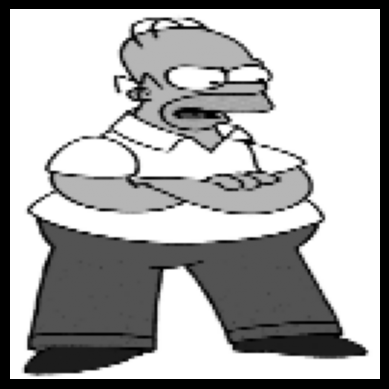

In [79]:
display_image(test_image.reshape(width, height))

In [80]:
network1_loaded.predict(test_image)[0][0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step


np.float32(0.99590033)

In [81]:
if network1_loaded.predict(test_image)[0][0] < 0.5:
  print('Bart')
else:
  print('Homer')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Homer


## Approach 2 - feature extraction

### Feature extractor

In [82]:
files = [
    os.path.join(directory, f) for f in sorted(os.listdir(directory)) if f.lower().endswith(('.bmp', '.png', '.jpg', '.jpeg'))
]
print(files)

['./homer_bart_1/bart1.bmp', './homer_bart_1/bart10.bmp', './homer_bart_1/bart100.bmp', './homer_bart_1/bart101.bmp', './homer_bart_1/bart102.bmp', './homer_bart_1/bart103.bmp', './homer_bart_1/bart104.bmp', './homer_bart_1/bart105.bmp', './homer_bart_1/bart106.bmp', './homer_bart_1/bart108.bmp', './homer_bart_1/bart109.bmp', './homer_bart_1/bart11.bmp', './homer_bart_1/bart110.bmp', './homer_bart_1/bart111.bmp', './homer_bart_1/bart112.bmp', './homer_bart_1/bart113.bmp', './homer_bart_1/bart114.bmp', './homer_bart_1/bart115.bmp', './homer_bart_1/bart116.bmp', './homer_bart_1/bart117.bmp', './homer_bart_1/bart118.bmp', './homer_bart_1/bart119.bmp', './homer_bart_1/bart12.bmp', './homer_bart_1/bart120.bmp', './homer_bart_1/bart121.bmp', './homer_bart_1/bart122.bmp', './homer_bart_1/bart123.bmp', './homer_bart_1/bart124.bmp', './homer_bart_1/bart125.bmp', './homer_bart_1/bart126.bmp', './homer_bart_1/bart127.bmp', './homer_bart_1/bart128.bmp', './homer_bart_1/bart13.bmp', './homer_bart_1

In [83]:
export = 'mouth,pants,shoes,tshirt,shorts,sneakers,class\n'

In [84]:
show_images = False
features = []

In [85]:
100 * 200

20000

In [86]:
(2000 / 20000) * 100

10.0

In [87]:
100 / 2

50.0

In [88]:
features = []
export = 'mouth,pants,shoes,tshirt,shorts,sneakers,class\n'

for image_path in files:
  # print(image_path)
  original_image = cv2.imread(image_path)
  if original_image is None:
    continue
  (H, W) = original_image.shape[:2]

  image = original_image.copy()
  image_features = []
  mouth = pants = shoes = 0
  tshirt = shorts = sneakers = 0

  image_name = os.path.basename(os.path.normpath(image_path))

  if image_name.startswith('b'):
    class_name = 0
  else:
    class_name = 1

  for row in range(0, H):
    for column in range(0, W):
      blue = image.item(row, column, 0)
      green = image.item(row, column, 1)
      red = image.item(row, column, 2)

      # Homer - brown mouth
      if (blue >= 95 and blue <= 140 and green >= 160 and green <= 185 and red >= 175 and red <= 200):
        image[row, column] = [0, 255, 255]
        mouth += 1

      # Homer - blue pants
      if (blue >= 150 and blue <= 180 and green >= 98 and green <= 120 and red >= 0 and red <= 90):
        image[row, column] = [0, 255, 255]
        pants += 1

      # Homer - gray shoes
      if row > (H / 2):
        if (blue >= 25 and blue <= 45 and green >= 25 and green <= 45 and red >= 25 and red <= 45):
          image[row, column] = [0, 255, 255]
          shoes += 1

      # Bart - orange t-shirt
      if (blue >= 11 and blue <= 22 and green >= 85 and green <= 105 and red >= 240 and red <= 255):
        image[row, column] = [0, 255, 128]
        tshirt += 1

      # Bart - blue shorts
      if (blue >= 125 and blue <= 170 and green >= 0 and green <= 12 and red >= 0 and red <= 20):
        image[row, column] = [0, 255, 128]
        shorts += 1

      # Bart - blue sneakers
      if row > (H / 2):
        if (blue >= 125 and blue <= 170 and green >= 0 and green <= 12 and red >= 0 and red <= 20):
          image[row, column] = [0, 255, 128]
          sneakers += 1

  mouth = round((mouth / (H * W)) * 100, 9)
  pants = round((pants / (H * W)) * 100, 9)
  shoes = round((shoes / (H * W)) * 100, 9)

  tshirt = round((tshirt / (H * W)) * 100, 9)
  shorts = round((shorts / (H * W)) * 100, 9)
  sneakers = round((sneakers / (H * W)) * 100, 9)

  image_features.append(mouth)
  image_features.append(pants)
  image_features.append(shoes)
  image_features.append(tshirt)
  image_features.append(shorts)
  image_features.append(sneakers)
  image_features.append(class_name)

  features.append(image_features)

  # print('Homer mouth: %s - Homer pants: %s - Homer shoes: %s' % (image_features[0], image_features[1], image_features[2]))
  # print('Bart t-shirt: %s - Bart shorts: %s - Bart sneakers: %s' % (image_features[3], image_features[4], image_features[5]))

  f = (",".join([str(item) for item in image_features]))
  export += f + '\n'

  if show_images == True:
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)
    fig, im = plt.subplots(1, 2)
    im[0].axis('off')
    im[0].imshow(original_image)
    im[1].axis('off')
    im[1].imshow(image)
    plt.show()

In [89]:
export

'mouth,pants,shoes,tshirt,shorts,sneakers,class\n0.0,0.0,0.114799225,6.886101887,3.495204355,3.495204355,0\n0.0,0.0,0.11007847,5.004901113,3.183888705,3.183888705,0\n0.0,0.0,0.182518631,5.264620437,5.029682961,5.029682961,0\n0.0,0.480168257,0.080028043,0.0,0.0,0.0,0\n0.0,0.0,0.029707562,8.978929368,3.459119497,3.459119497,0\n0.0,0.0,0.053304904,6.75432362,0.948827292,0.948827292,0\n0.249585206,0.0,0.019853369,9.693407263,4.104683977,4.104683977,0\n0.0,0.0,0.181208054,0.0,0.0,0.0,0\n0.0,0.0,0.148868778,0.0,0.0,0.0,0\n0.0,0.0,0.114762211,9.594752524,7.522715548,7.522715548,0\n0.0,0.0,0.138655462,0.0,0.0,0.0,0\n0.0,0.0,0.02400947,19.545383481,0.0,0.0,0\n0.00307645,0.0,0.0,6.495154592,5.599138594,5.599138594,0\n0.001317263,0.0,0.087817515,0.0,0.0,0.0,0\n0.0,0.0,0.032184591,8.395721925,0.0,0.0,0\n0.02105732,0.0,0.008503918,8.915750471,0.0,0.0,0\n0.0,0.0,0.081055114,11.095816228,4.525111363,4.525111363,0\n0.0,0.0,0.08757526,10.443349754,3.183296307,3.183296307,0\n0.0,0.0,0.043806812,9.497408

In [90]:
with open('features.csv', 'w') as file:
  for l in export:
    file.write(l)
file.closed

True

In [91]:
dataset = pd.read_csv('features.csv')
dataset

,mouth,pants,shoes,tshirt,shorts,sneakers,class
0,0.000000,0.000000,0.114799,6.886102,3.495204,3.495204,0
1,0.000000,0.000000,0.110078,5.004901,3.183889,3.183889,0
2,0.000000,0.000000,0.182519,5.264620,5.029683,5.029683,0
3,0.000000,0.480168,0.080028,0.000000,0.000000,0.000000,0
4,0.000000,0.000000,0.029708,8.978929,3.459119,3.459119,0
...,...,...,...,...,...,...,...
264,6.485412,0.000000,0.171985,0.000000,0.000000,0.000000,1
265,0.000000,0.000000,0.161637,0.000000,0.000000,0.000000,1
266,4.264975,0.000000,0.329940,0.000000,0.000000,0.000000,1
267,1.429133,0.000000,0.034559,0.000000,0.000000,0.000000,1


### Train and test sets

In [92]:
X = dataset.iloc[:, 0:6].values
X

array([[ 0.        ,  0.        ,  0.11479923,  6.88610189,  3.49520435,
         3.49520435],
       [ 0.        ,  0.        ,  0.11007847,  5.00490111,  3.18388871,
         3.18388871],
       [ 0.        ,  0.        ,  0.18251863,  5.26462044,  5.02968296,
         5.02968296],
       ...,
       [ 4.26497522,  0.        ,  0.32993967,  0.        ,  0.        ,
         0.        ],
       [ 1.42913348,  0.        ,  0.03455866,  0.        ,  0.        ,
         0.        ],
       [ 0.853902  , 13.74424774,  0.16177802,  0.        ,  0.        ,
         0.        ]], shape=(269, 6))

In [93]:
y = dataset.iloc[:, 6].values
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1])

In [94]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

In [95]:
X_train.shape, y_train.shape

((215, 6), (215,))

In [96]:
X_test.shape, y_test.shape

((54, 6), (54,))

### Building and training the neural network

In [125]:
# 6 -> 4 -> 4 -> 4 -> 1
network2 = tf.keras.models.Sequential()
network2.add(tf.keras.layers.Input(shape=(6,)))
network2.add(tf.keras.layers.Dense(units = 4, activation='relu'))
network2.add(tf.keras.layers.Dense(units = 4, activation='relu'))
network2.add(tf.keras.layers.Dense(units = 4, activation='relu'))
network2.add(tf.keras.layers.Dense(units = 1, activation='sigmoid'))

In [99]:
network2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 4)              │            28 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 73 (292.00 B)

 Trainable params: 73 (292.00 B)

 Non-trainable params: 0 (0.00 B)

In [100]:
network2.compile(optimizer='Adam', loss='binary_crossentropy', metrics = ['accuracy'])

In [101]:
history = network2.fit(X_train, y_train, epochs = 50)

Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.4093 - loss: 0.9172
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4233 - loss: 0.8920 
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4326 - loss: 0.8695 
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4186 - loss: 0.8478 
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4233 - loss: 0.8291 
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4279 - loss: 0.8111 
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4279 - loss: 0.7950 
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4233 - loss: 0.7792 
Epoch 9/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4186 - loss: 0.7651 
Epoch 10/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4233 - loss: 0.7516 
Epoch 11/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4186 - loss: 0.7382 
Epoch 12/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4093 - loss: 0.7269 
E

### Evaluating the neural network

In [102]:
history.history.keys()

dict_keys(['accuracy', 'loss'])

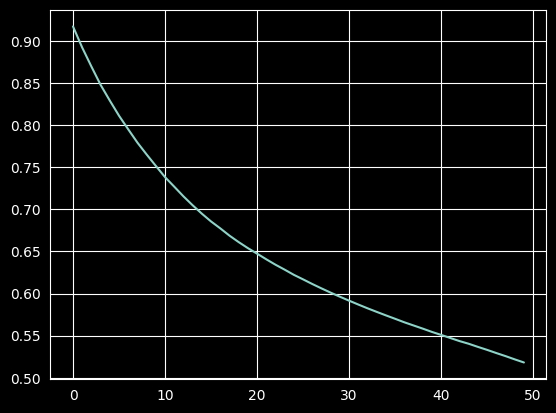

In [103]:
plt.plot(history.history['loss']);

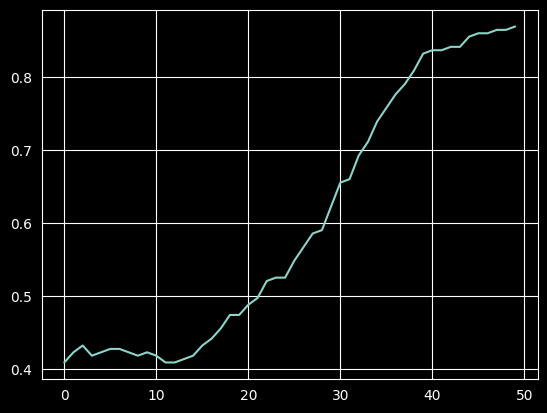

In [104]:
plt.plot(history.history['accuracy']);

In [105]:
X_test.shape

(54, 6)

In [106]:
predictions = network2.predict(X_test)
predictions

1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/stepWARNING:tensorflow:5 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7ff0583abe20> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step


array([[0.9581102 ],
       [0.84158903],
       [0.46605143],
       [0.46227297],
       [0.4672059 ],
       [0.52939653],
       [0.43601367],
       [0.43127275],
       [0.4637692 ],
       [0.4275029 ],
       [0.93861073],
       [0.46507767],
       [0.44247535],
       [0.46531603],
       [0.46382654],
       [0.4436897 ],
       [0.4275029 ],
       [0.4629451 ],
       [0.9303164 ],
       [0.43474543],
       [0.55598336],
       [0.77693206],
       [0.4275029 ],
       [0.5010857 ],
       [0.4651135 ],
       [0.9309213 ],
       [0.50092256],
       [0.4625498 ],
       [0.43238142],
       [0.4720763 ],
       [0.4648775 ],
       [0.46661046],
       [0.47051358],
       [0.82730705],
       [0.99879277],
       [0.4275029 ],
       [0.4507771 ],
       [0.43043852],
       [0.43292695],
       [0.9626334 ],
       [0.92734545],
       [0.44346738],
       [0.42872682],
       [0.9882023 ],
       [0.99999785],
       [0.5140565 ],
       [0.42848232],
       [0.483

In [107]:
predictions = (predictions > 0.5)
predictions

array([[ True],
       [ True],
       [False],
       [False],
       [False],
       [ True],
       [False],
       [False],
       [False],
       [False],
       [ True],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [ True],
       [False],
       [ True],
       [ True],
       [False],
       [ True],
       [False],
       [ True],
       [ True],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [ True],
       [ True],
       [False],
       [False],
       [False],
       [False],
       [ True],
       [ True],
       [False],
       [False],
       [ True],
       [ True],
       [ True],
       [False],
       [False],
       [False],
       [ True],
       [False],
       [False],
       [False],
       [False]])

In [108]:
y_test

array([1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1,
       1, 1, 0, 1, 0, 1, 0, 0, 0, 0])

In [109]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, predictions) # 0.68

0.8888888888888888

In [110]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, predictions)
cm

array([[31,  1],
       [ 5, 17]])

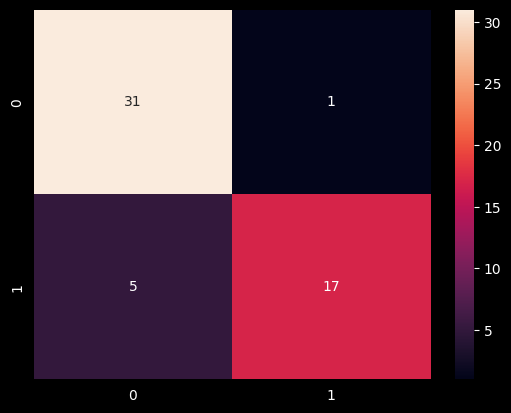

In [111]:
sns.heatmap(cm, annot=True);

In [112]:
from sklearn.metrics import classification_report
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.86      0.97      0.91        32
           1       0.94      0.77      0.85        22

    accuracy                           0.89        54
   macro avg       0.90      0.87      0.88        54
weighted avg       0.90      0.89      0.89        54



### Saving, loading and classifying one image

In [113]:
model_json = network2.to_json()
with open('network2.json','w') as json_file:
  json_file.write(model_json)

In [114]:
network2.save_weights('network2.weights.h5')

In [115]:
with open('network2.json', 'r') as json_file:
  json_saved_model = json_file.read()
json_saved_model

'{"module": "keras", "class_name": "Sequential", "config": {"name": "sequential_1", "trainable": true, "dtype": {"module": "keras", "class_name": "DTypePolicy", "config": {"name": "float32"}, "registered_name": null}, "layers": [{"module": "keras.layers", "class_name": "InputLayer", "config": {"batch_shape": [null, 6], "dtype": "float32", "sparse": false, "ragged": false, "name": "input_layer_1", "optional": false}, "registered_name": null}, {"module": "keras.layers", "class_name": "Dense", "config": {"name": "dense_3", "trainable": true, "dtype": {"module": "keras", "class_name": "DTypePolicy", "config": {"name": "float32"}, "registered_name": null}, "units": 4, "activation": "relu", "use_bias": true, "kernel_initializer": {"module": "keras.initializers", "class_name": "GlorotUniform", "config": {"seed": null, "input_axes": null, "output_axes": null}, "registered_name": null}, "bias_initializer": {"module": "keras.initializers", "class_name": "Zeros", "config": {}, "registered_name": 

In [116]:
network2_loaded = tf.keras.models.model_from_json(json_saved_model)
network2_loaded.load_weights('network2.weights.h5')
network2_loaded.compile(loss = 'binary_crossentropy', optimizer='Adam', metrics=['accuracy'])

In [117]:
network2_loaded.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 4)              │            28 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 73 (292.00 B)

 Trainable params: 73 (292.00 B)

 Non-trainable params: 0 (0.00 B)

In [118]:
test_image = X_test[0]
test_image

array([1.08537616, 8.20287405, 0.22541561, 0.        , 0.        ,
       0.        ])

In [119]:
test_image.shape

(6,)

In [120]:
test_image = test_image.reshape(1,-1)
test_image.shape

(1, 6)

In [123]:
network2_loaded.predict(test_image)[0][0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


np.float32(0.9581102)

In [122]:
if network2_loaded.predict(test_image)[0][0] < 0.5:
  print('Bart')
else:
  print('Homer')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
Homer
